In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report

In [15]:
print("LOADING FASHION MNIST DATASET...")
X, y = fetch_openml(
    'Fashion-MNIST',
    version=1,
    return_X_y=True,
    as_frame=False
)
x=X.astype('float32')
y=y.astype('int')
print('dataset SHAPE',x.shape)

LOADING FASHION MNIST DATASET...
dataset SHAPE (70000, 784)


In [16]:
x=x[:10000]
y=y[:10000]

In [17]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training sample:",x_train.shape[0])
print("Testing samples:",x_test.shape[0])

Training sample: 8000
Testing samples: 2000


In [21]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [25]:
print("training linear SVM...")
linear_svm=SVC(kernel='linear')
linear_svm.fit(x_train,y_train)
y_pred_linear=linear_svm.predict(x_test)
linear_accuracy=accuracy_score(y_test,y_pred_linear)
print("linear SVM Accuracy:",linear_accuracy *100,"%")

training linear SVM...
linear SVM Accuracy: 80.75 %


In [28]:
print("training RBF SVM..")
rbf_svm=SVC(
    kernel='rbf',
    gamma='scale')
rbf_svm.fit(x_train,y_train)
y_pred_rbf=rbf_svm.predict(x_test)
rbf_accuracy=accuracy_score(y_test,y_pred_rbf)
print("rbf SVM Accuracy:",rbf_accuracy*100,"%")

training RBF SVM..
rbf SVM Accuracy: 85.25 %


In [32]:
print("---LINEAR SVM CLASSIFICATION REPORT---")
print(classification_report(y_test,y_pred_linear))
print("---RBF Classsifv=cation Report---")
print(classification_report(y_test,y_pred_rbf))

---LINEAR SVM CLASSIFICATION REPORT---
              precision    recall  f1-score   support

           0       0.68      0.83      0.74       189
           1       0.95      0.97      0.96       205
           2       0.64      0.71      0.67       203
           3       0.83      0.79      0.81       204
           4       0.65      0.62      0.63       195
           5       0.91      0.92      0.91       198
           6       0.63      0.50      0.55       204
           7       0.89      0.89      0.89       204
           8       0.97      0.95      0.96       198
           9       0.92      0.92      0.92       200

    accuracy                           0.81      2000
   macro avg       0.81      0.81      0.81      2000
weighted avg       0.81      0.81      0.81      2000

---RBF Classsifv=cation Report---
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       189
           1       1.00      0.96      0.98       205
     

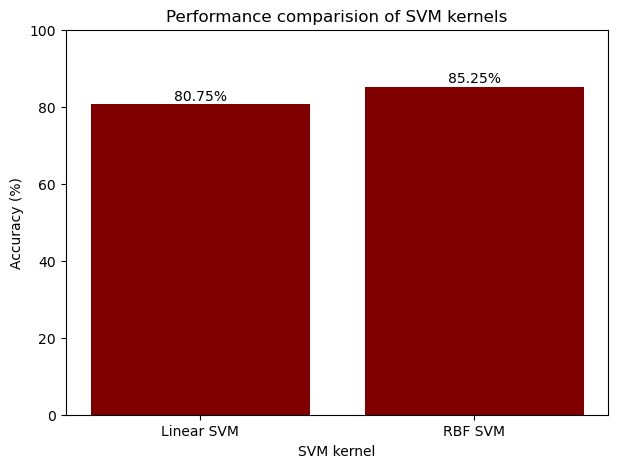

In [39]:
models=['Linear SVM','RBF SVM']
accuracy=[linear_accuracy*100,rbf_accuracy*100]
plt.figure(figsize=(7,5))
bars=plt.bar(models,accuracy)
plt.ylabel("Accuracy (%)")
plt.xlabel("SVM kernel")
plt.title("Performance comparision of SVM kernels")
plt.ylim(0,100)
for bar,value in zip(bars,accuracy):
    plt.text(
        bar.get_x()+ bar.get_width()/2,
        value+1,
        f"{value:.2f}%",
        ha='center')
plt.show()